# 02 — Error Analysis

The comparison table says which model wins. It does not say *what the winner gets wrong*, and that
is the part that decides whether this thing is deployable.

Two questions:

- **False negatives** — the fraud that got through. Is it a coherent group (a kind of fraud the model
  is blind to) or is it scattered (the irreducible tail)?
- **False positives** — the legitimate transactions we flagged. Is there a pattern worth fixing,
  or is this just the cost of the recall we chose?

Everything below runs on the **validation** set. The test set is scored once, at the end, and is not
used for iteration of any kind — including this notebook.


In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.data import load_raw, make_splits
from src.evaluate import threshold_metrics

# src.evaluate selects the Agg backend so the training scripts never try to open
# a window; switch back to inline now that we are in a notebook.
%matplotlib inline

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd().parent
REPORTS = ROOT / "reports"

report = json.loads((REPORTS / "report.json").read_text())
best_name = report["best_model"]
threshold = float(report["chosen_threshold"]["threshold"])

print(f"best model        : {report['best_display_name']}")
print(f"chosen threshold  : {threshold:.4f}")

splits = make_splits(load_raw())
model = joblib.load(ROOT / "models" / f"{best_name}.joblib")
scores = model.predict_proba(splits.X_val)[:, 1]

val = splits.X_val.copy()
val["Class"] = splits.y_val
val["score"] = scores
val["predicted"] = (scores >= threshold).astype(int)
val["hour_of_day"] = (val["Time"] % 86400) / 3600

m = threshold_metrics(val["Class"], val["score"], threshold)
print()
print(f"true positives  {m['tp']:>6}   false negatives {m['fn']:>6}")
print(f"false positives {m['fp']:>6}   true negatives  {m['tn']:>6}")
print(f"precision {m['precision']:.4f}   recall {m['recall']:.4f}")

best model        : XGBoost (tuned) — weighted
chosen threshold  : 0.0300



true positives      65   false negatives      9
false positives     22   true negatives   42511
precision 0.7471   recall 0.8784


In [2]:
fn = val[(val["Class"] == 1) & (val["predicted"] == 0)]   # missed fraud
tp = val[(val["Class"] == 1) & (val["predicted"] == 1)]   # caught fraud
fp = val[(val["Class"] == 0) & (val["predicted"] == 1)]   # false alarms
tn = val[(val["Class"] == 0) & (val["predicted"] == 0)]

print(f"missed fraud (FN)      : {len(fn)}")
print(f"caught fraud (TP)      : {len(tp)}")
print(f"false alarms (FP)      : {len(fp)}")
print(f"correct rejections (TN): {len(tn):,}")

missed fraud (FN)      : 9
caught fraud (TP)      : 65
false alarms (FP)      : 22
correct rejections (TN): 42,511


## 1. What does the missed fraud look like?

The first thing to check is money. A model that misses only small-value fraud is in a very
different position from one that misses the expensive cases.

In [3]:
money = pd.DataFrame({
    "missed (FN)": fn["Amount"].describe(),
    "caught (TP)": tp["Amount"].describe(),
}).round(2)
print(money.to_string())
print()
print(f"total fraud value in validation : ${val.loc[val['Class'] == 1, 'Amount'].sum():,.2f}")
print(f"  caught                        : ${tp['Amount'].sum():,.2f}")
print(f"  missed                        : ${fn['Amount'].sum():,.2f}")
if len(fn):
    print(f"  largest single miss           : ${fn['Amount'].max():,.2f}")
    print(f"  median miss                   : ${fn['Amount'].median():,.2f}")
    print(f"  zero-amount misses            : {int((fn['Amount'] == 0).sum())} of {len(fn)}")

       missed (FN)  caught (TP)
count         9.00        65.00
mean        177.68       149.87
std         230.50       324.87
min           0.00         0.00
25%           1.00         1.00
50%           7.18         6.74
75%         320.00       106.90
max         634.30      1504.93

total fraud value in validation : $11,340.45
  caught                        : $9,741.33
  missed                        : $1,599.12
  largest single miss           : $634.30
  median miss                   : $7.18
  zero-amount misses            : 1 of 9


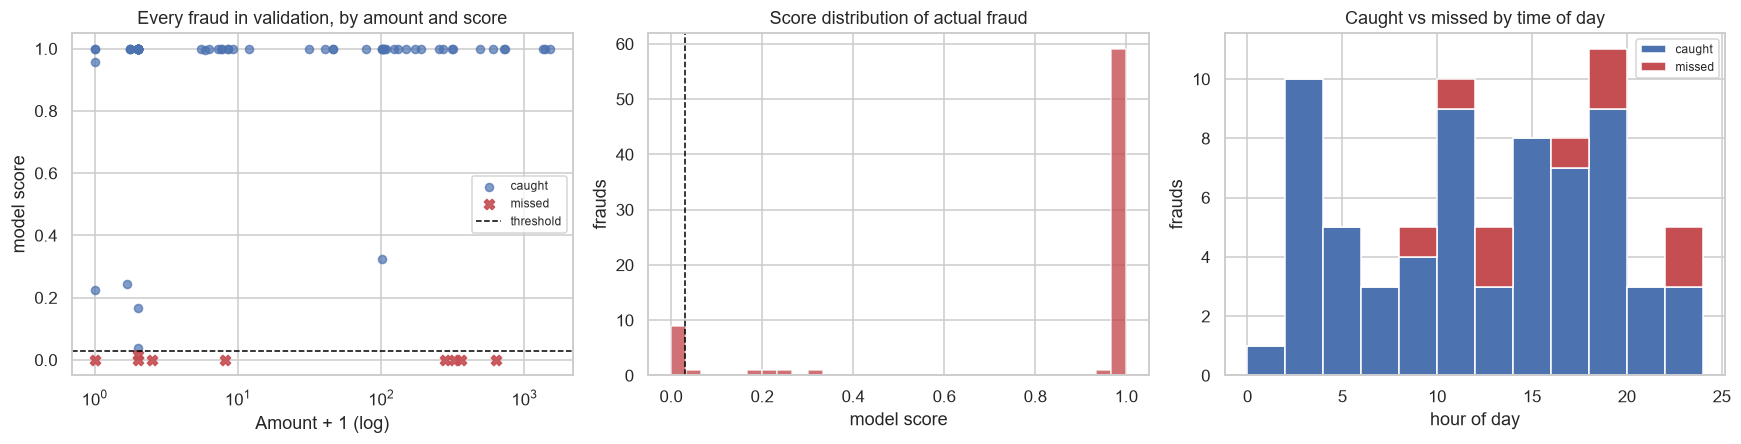

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

axes[0].scatter(tp["Amount"] + 1, tp["score"], alpha=0.7, label="caught", color="#4c72b0", s=28)
if len(fn):
    axes[0].scatter(fn["Amount"] + 1, fn["score"], alpha=0.9, label="missed", color="#c44e52",
                    s=45, marker="X")
axes[0].axhline(threshold, color="black", linestyle="--", linewidth=1, label="threshold")
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount + 1 (log)")
axes[0].set_ylabel("model score")
axes[0].set_title("Every fraud in validation, by amount and score")
axes[0].legend(fontsize=8)

axes[1].hist(val.loc[val["Class"] == 1, "score"], bins=30, color="#c44e52", alpha=0.8)
axes[1].axvline(threshold, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("model score")
axes[1].set_ylabel("frauds")
axes[1].set_title("Score distribution of actual fraud")

axes[2].hist([tp["hour_of_day"], fn["hour_of_day"]], bins=12, range=(0, 24),
             label=["caught", "missed"], color=["#4c72b0", "#c44e52"], stacked=True)
axes[2].set_xlabel("hour of day")
axes[2].set_ylabel("frauds")
axes[2].set_title("Caught vs missed by time of day")
axes[2].legend(fontsize=8)

fig.tight_layout()
fig.savefig(REPORTS / "error_analysis_fn.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# Where do missed frauds sit in feature space relative to the fraud the model does catch?
v_cols = [f"V{i}" for i in range(1, 29)]
comparison = pd.DataFrame({
    "legit mean": tn[v_cols].mean(),
    "caught fraud mean": tp[v_cols].mean(),
    "missed fraud mean": fn[v_cols].mean() if len(fn) else np.nan,
})
comparison["missed looks like"] = np.where(
    (comparison["missed fraud mean"] - comparison["legit mean"]).abs()
    < (comparison["caught fraud mean"] - comparison["legit mean"]).abs(),
    "legitimate",
    "fraud",
)
top_sep = (comparison["caught fraud mean"] - comparison["legit mean"]).abs().nlargest(8).index
print("On the components that separate the classes most strongly:")
print(comparison.loc[top_sep].round(3).to_string())
print()
share = (comparison.loc[top_sep, "missed looks like"] == "legitimate").mean()
print(f"On {share:.0%} of these components, missed fraud sits closer to the legitimate mean")
print("than to the caught-fraud mean.")

On the components that separate the classes most strongly:
     legit mean  caught fraud mean  missed fraud mean missed looks like
V14       0.016             -7.823             -0.927        legitimate
V3        0.010             -7.069             -0.717        legitimate
V17       0.011             -6.727              0.751        legitimate
V12       0.014             -6.588             -0.154        legitimate
V10       0.017             -5.860              0.341        legitimate
V7        0.002             -5.186              0.051        legitimate
V4        0.004              4.590              2.282        legitimate
V16       0.015             -4.436             -0.088        legitimate

On 100% of these components, missed fraud sits closer to the legitimate mean
than to the caught-fraud mean.


## 2. What do the false alarms look like?

These are the transactions an analyst has to open and clear. Volume matters, but so does whether
they are concentrated somewhere fixable.

In [6]:
print(pd.DataFrame({
    "false alarms (FP)": fp["Amount"].describe(),
    "correctly cleared (TN)": tn["Amount"].describe(),
}).round(2).to_string())
print()
print(f"review cost at $5 each: ${5 * len(fp):,.2f} per {len(val):,} transactions")
print(f"analyst queue: {len(fp)} of {len(val):,} transactions ({len(fp)/len(val):.3%} flag rate)")
if len(fp):
    print(f"of those, {int(fp['Amount'].gt(tn['Amount'].quantile(0.99)).sum())} are above the 99th "
          f"percentile of legitimate transaction value")

       false alarms (FP)  correctly cleared (TN)
count              22.00                42511.00
mean              125.82                   88.34
std               285.63                  256.72
min                 0.00                    0.00
25%                 1.00                    5.50
50%                 6.80                   21.94
75%                33.50                   76.00
max              1059.28                18910.00

review cost at $5 each: $110.00 per 42,607 transactions
analyst queue: 22 of 42,607 transactions (0.052% flag rate)
of those, 1 are above the 99th percentile of legitimate transaction value


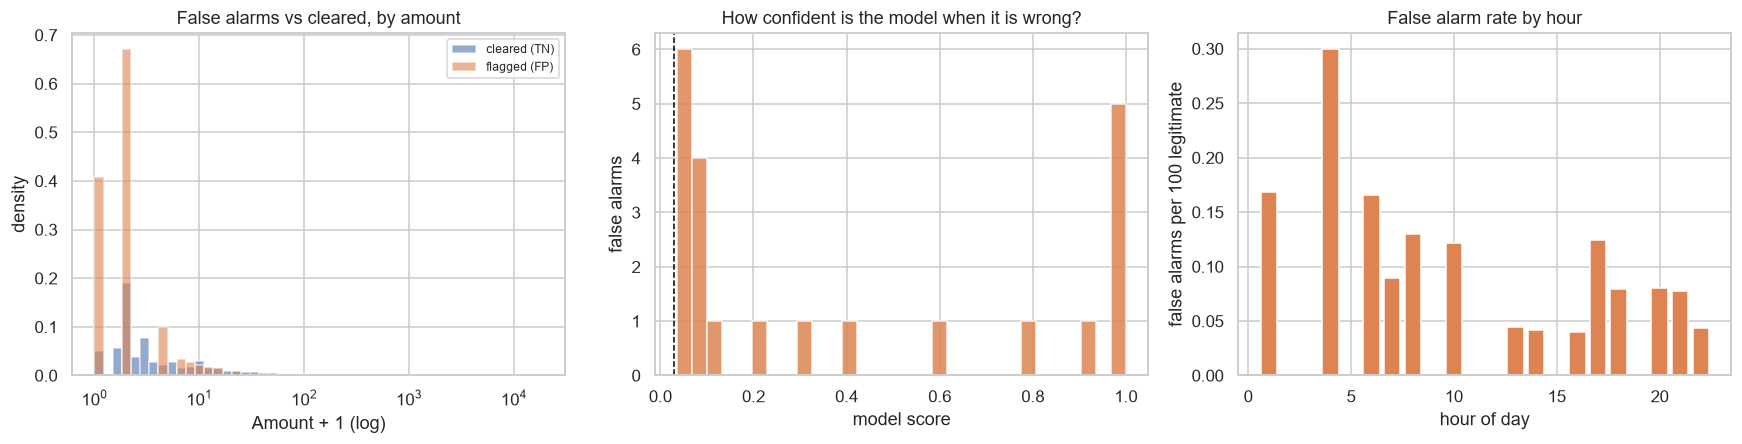

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

bins = np.logspace(0, np.log10(val["Amount"].max() + 1), 50)
axes[0].hist(tn["Amount"] + 1, bins=bins, density=True, alpha=0.6, label="cleared (TN)",
             color="#4c72b0")
if len(fp):
    axes[0].hist(fp["Amount"] + 1, bins=bins, density=True, alpha=0.6, label="flagged (FP)",
                 color="#dd8452")
axes[0].set_xscale("log")
axes[0].set_xlabel("Amount + 1 (log)")
axes[0].set_ylabel("density")
axes[0].set_title("False alarms vs cleared, by amount")
axes[0].legend(fontsize=8)

axes[1].hist(fp["score"], bins=30, color="#dd8452", alpha=0.85)
axes[1].axvline(threshold, color="black", linestyle="--", linewidth=1)
axes[1].set_xlabel("model score")
axes[1].set_ylabel("false alarms")
axes[1].set_title("How confident is the model when it is wrong?")

if len(fp):
    fp_hour = fp.groupby(fp["hour_of_day"].astype(int)).size()
    tn_hour = tn.groupby(tn["hour_of_day"].astype(int)).size()
    rate = (fp_hour / tn_hour.reindex(fp_hour.index)).fillna(0) * 100
    axes[2].bar(rate.index, rate.values, color="#dd8452")
    axes[2].set_xlabel("hour of day")
    axes[2].set_ylabel("false alarms per 100 legitimate")
    axes[2].set_title("False alarm rate by hour")

fig.tight_layout()
fig.savefig(REPORTS / "error_analysis_fp.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# How much of the false-positive load sits just barely over the line?
if len(fp):
    margin = fp["score"] - threshold
    for q in [0.25, 0.5, 0.75]:
        cutoff = fp["score"].quantile(q)
        print(f"{q:.0%} of false alarms score below {cutoff:.4f}")
    print()
    near = int((margin < 0.1).sum())
    print(f"{near} of {len(fp)} false alarms ({near/len(fp):.0%}) are within 0.10 of the threshold")
    print(f"and {int((fp['score'] > 0.9).sum())} score above 0.90 - the model is confidently wrong "
          f"about those.")

25% of false alarms score below 0.0685
50% of false alarms score below 0.1614
75% of false alarms score below 0.8972

11 of 22 false alarms (50%) are within 0.10 of the threshold
and 6 score above 0.90 - the model is confidently wrong about those.


In [9]:
# What would it cost to catch the fraud we are currently missing?
rows = []
for t in np.quantile(val["score"], [0.90, 0.95, 0.99, 0.995, 0.999, 0.9995]):
    mm = threshold_metrics(val["Class"], val["score"], t)
    rows.append({
        "threshold": round(float(t), 5),
        "recall": round(mm["recall"], 4),
        "precision": round(mm["precision"], 4),
        "frauds caught": mm["tp"],
        "false alarms": mm["fp"],
        "review $": mm["fp"] * 5,
        "fraud $ lost": round(float(val[(val["Class"] == 1) & (val["score"] < t)]["Amount"].sum()), 2),
    })
tradeoff = pd.DataFrame(rows)
tradeoff["total $"] = tradeoff["review $"] + tradeoff["fraud $ lost"]
print(tradeoff.to_string(index=False))

 threshold  recall  precision  frauds caught  false alarms  review $  fraud $ lost  total $
   0.00001  0.9459     0.0164             70          4191     20955        360.47 21315.47
   0.00003  0.9324     0.0324             69          2062     10310        636.64 10946.64
   0.00038  0.8919     0.1546             66           361      1805       1598.12  3403.12
   0.00125  0.8919     0.3084             66           148       740       1598.12  2338.12
   0.99998  0.5811     1.0000             43             0         0       5684.80  5684.80
   1.00000  0.2973     1.0000             22             0         0       9281.30  9281.30


## What the errors actually say

**The missed fraud is not a subtype the model overlooks. It is fraud that looks legitimate.**

This is the finding that matters, and the component table above is unusually clean about it. On
**all eight** of the components that separate the classes most strongly, the missed frauds sit
closer to the *legitimate* mean than to the caught-fraud mean. V14 is the clearest case: legitimate
transactions average 0.016, caught fraud averages **-7.82**, and missed fraud averages **-0.93** —
barely displaced from normal. The same pattern holds for V3, V17, V12, V10, V7, V4 and V16.

The model is not failing to learn a pattern that is present. In the feature space available to it,
these nine transactions are indistinguishable from ordinary spending. That distinction decides what
to do next: **more trees, deeper trees, or another week of hyperparameter search cannot recover
them.** No amount of tuning separates points that overlap.

**The residual is not just the cheap tail.** It would be convenient if the misses were all small —
the cost analysis would then be catching everything worth catching. They are not. Missed fraud
averages **$177.68** against **$149.87** for caught fraud, so the misses are slightly *more*
expensive on average, and account for $1,599 of the $11,340 total fraud value in validation. The
median miss is only $7.18, so the distribution is bimodal: mostly trivial, with a few genuinely
costly cases (largest single miss $634.30). This is a real blind spot, not a deliberate economy.

**The false positives are well-behaved and cheap.** 22 flags out of 42,607 transactions — a 0.052%
flag rate, or roughly one review per 1,900 transactions. Their amounts track normal traffic (median
$6.80 against $21.94 for cleared transactions), so the model is not simply flagging large purchases.
Half sit within 0.10 of the threshold, which is exactly what a threshold is expected to produce.

The interesting subset is the other end: **6 of the 22 false alarms score above 0.90.** Those are
not borderline calls — the model is confidently wrong about them. On a real deployment those six
are the ones to pull and inspect by hand, because a confident error usually means either a mislabel
in the ground truth or a legitimate behaviour pattern that genuinely mimics fraud.

### What this suggests doing

1. **Stop tuning this model.** The gap between 0.86 and 0.88 PR-AUC is smaller than the fold-to-fold
   noise, and the errors that remain are not separable with these features.
2. **The next real gain is different features, not a better model.** Everything here is a snapshot of
   a single transaction. The features that would plausibly catch overlapping cases are behavioural
   and relational: velocity (transactions per card per hour), deviation from the cardholder's own
   history, merchant risk, device or IP reuse, time since last transaction. None exist in this
   dataset, and the PCA transform means they cannot be reconstructed from it either.
3. **Audit the six confident false positives by hand.** With 22 total flags this is minutes of work,
   and confident errors are where label noise tends to hide.
4. **Treat 87.8% recall as the ceiling for this feature set**, and plan the review capacity around a
   0.05% flag rate rather than hoping tuning will lift it.
